# A1: CNN vs Transformer on Food-101 (replication notebook)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/broistg/deep-learning-CO5085/blob/main/A1/notebooks/A1.ipynb)

Thin notebook: all code lives in `A1/a1lib/` and `common/`. The full experiment (77 runs, about 25 GPU-hours) cannot be repeated in a notebook session, so there are three levels, chosen with `MODE`:

| `MODE` | What it does | Runtime | Time |
|---|---|---|---|
| `"load"` (default) | Takes the **committed results** (`A1/results/*.json`) and the **released test logits**, regenerates every table and figure of the report (accuracy, seeds, cost, data-scale ablation, calibration, ensembles, error analysis) and **asserts that the tables equal the report's** | free Colab, CPU is enough | a few minutes |
| `"evaluate"` | Downloads the **released weights** of the 8 core runs, re-evaluates them on the 25,250 test images and checks that the accuracy equals the published one (needs the Food-101 data: about 4.65 GB download + 15 min resize) | GPU runtime | about 40 min |
| `"rerun"` | **Retrains** the runs listed in `RERUN_RUNS` with the original configs and compares with the published results (default: ResNet-50 linear probing, 10 epochs, about 40 min on a T4). Listing all 8 core runs costs about 10 GPU-hours | GPU runtime | see `RERUN_RUNS` |

A retrain reproduces the published numbers bit by bit only on the same GPU type (Tesla T4, as on Kaggle and Colab); on other GPUs it agrees within the seed-to-seed spread, which is how the notebook judges it. Protocol and decisions: `A1/README.md`, `A1/TEAM_PROTOCOL.md`.

In [1]:
# 0. Settings
MODE = "load"                         # "load", "evaluate" or "rerun"
FETCH_LOGITS = True                   # load mode: download the released test logits (about 100 MB) for calibration/ensemble/error analyses
RERUN_RUNS = ["m_resnet50_head_s0"]   # rerun mode: which runs to retrain (ids from A1/configs/)
REPO_URL = "https://github.com/broistg/deep-learning-CO5085.git"
BRANCH = "main"

In [2]:
# 1. Code: clone or update the repo, install the dependencies (torch is NOT reinstalled), put the repo on the path
import os, sys
ON_COLAB = "google.colab" in sys.modules
REPO_DIR = "/content/repo" if ON_COLAB else os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if ON_COLAB and not os.path.isdir(REPO_DIR + "/.git"):
    !git clone -b {BRANCH} {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
if ON_COLAB:
    !git pull --ff-only
!pip install -q -r requirements/a1.txt
paths = [REPO_DIR, REPO_DIR + "/A1"]
os.environ["PYTHONPATH"] = os.pathsep.join(paths)
for q in paths:
    if q not in sys.path:
        sys.path.insert(0, q)
from common import notebook_utils as nu

Cloning into '/content/repo'...
remote: Enumerating objects: 668, done.
remote: Counting objects: 100% (668/668), done.
remote: Compressing objects: 100% (329/329), done.
remote: Total 668 (delta 366), reused 609 (delta 310), pack-reused 0 (from 0)
Receiving objects: 100% (668/668), 8.54 MiB | 27.17 MiB/s, done.
Resolving deltas: 100% (366/366), done.
/content/repo
Already up to date.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# 2. What this run will do
nu.banner(MODE, "A1")
import torch; print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())
if MODE in ("evaluate", "rerun"):
    assert torch.cuda.is_available(), "this mode needs a GPU runtime (Runtime > Change runtime type > T4)"
if MODE == "rerun":
    h, n = nu.estimate_hours("A1/results")
    print(f"All {n} published runs together took about {h:.1f} h; you selected {len(RERUN_RUNS)} run(s): {RERUN_RUNS}")

A1: MODE=load. Regenerates tables/figures from the committed results and checks them against the report. A free CPU runtime is enough; takes a few minutes.
torch 2.11.0+cpu | cuda: False


In [4]:
# 3. Tests (no GPU, no data): schedule, plan (77 runs), store/locks, per-sample seeding, analysis on synthetic results
!python -m unittest discover -s A1/tests
!python -m unittest discover -s common/tests

77 finished runs (28 in the main protocol); logits dir: /tmp/tmps08trqwa/artifacts (found)
wrote tab_ablation.tex, tab_acc.tex, tab_acc_ext.tex, tab_calibration.tex, tab_confpairs.tex, tab_ensemble.tex, tab_freeze.tex, tab_hardclasses.tex, tab_lr.tex, tab_seeds.tex, tab_stretch.tex, tab_traincost.tex + summary.json; figures in /tmp/tmps08trqwa/out/figures
77 finished runs (28 in the main protocol); logits dir: /tmp/tmps08trqwa/artifacts (found)
wrote tab_ablation.tex, tab_acc.tex, tab_acc_ext.tex, tab_calibration.tex, tab_confpairs.tex, tab_ensemble.tex, tab_freeze.tex, tab_hardclasses.tex, tab_lr.tex, tab_seeds.tex, tab_stretch.tex, tab_traincost.tex + summary.json; figures in /tmp/tmps08trqwa/out2/figures
......77 finished runs (28 in the main protocol); logits dir: /tmp/tmps08trqwa/nope (missing)
no logits found: calibration, ensemble and error analyses skipped (download a1_logits.zip from the Release)
wrote tab_ablation.tex, tab_acc.tex, tab_acc_ext.tex, tab_freeze.tex, tab_lr.tex,

## Load mode

In [5]:
# 4a. (load) released test logits, verified by SHA-256 -> A1/artifacts/<run>/logits_*.npz
if MODE == "load" and FETCH_LOGITS:
    try:
        nu.fetch_release("a1_logits.zip")
    except Exception as e:
        print("WARNING: logits not available; calibration, ensemble and error analyses will be skipped:", e)

downloading https://github.com/broistg/deep-learning-CO5085/releases/download/weights-v1/a1_logits.zip (225 MB)


In [6]:
# 4b. (load) regenerate all tables, figures and summary.json into A1/regenerated (nothing committed is overwritten)
if MODE == "load":
    !python -m a1lib.analyze --out A1/regenerated

88 finished runs (28 in the main protocol); logits dir: /content/repo/A1/artifacts (missing)
no logits found: calibration, ensemble and error analyses skipped (download a1_logits.zip from the Release)
wrote tab_ablation.tex, tab_acc.tex, tab_acc_ext.tex, tab_freeze.tex, tab_lr.tex, tab_seeds.tex, tab_stretch.tex, tab_traincost.tex + summary.json; figures in A1/regenerated/figures


In [7]:
# 4c. (load) check: regenerated tables == committed tables (byte for byte), summary.json numerically equal
if MODE == "load":
    nu.compare_outputs("A1/regenerated", "A1/results",
                       optional=("tab_calibration.tex", "tab_ensemble.tex", "tab_confpairs.tex", "tab_hardclasses.tex",
                                 "calibration", "ensemble_top1"))

(summary.json: 'errors' skipped, the logits were not downloaded)
(summary.json: 'calibration' skipped, the logits were not downloaded)
(summary.json: 'ensemble_top1' skipped, the logits were not downloaded)
OK   summary.json
All regenerated tables and numbers equal the committed (= reported) ones.


## Data (evaluate and rerun modes)

In [8]:
# 5a. Food-101 from the official source, resized to 256 px by the repo script (about 4.65 GB download, 10-15 min); checks the split hash
if MODE in ("evaluate", "rerun"):
    if not os.path.exists("/content/a1_cache/food101_256.tar"):
        !wget -q -c https://data.ethz.ch/cvl/food-101.tar.gz -O /content/food-101.tar.gz
        !tar -xzf /content/food-101.tar.gz -C /content
        !python -m a1lib.data build-cache --food-root /content/food-101 --shared-dir /content/a1_cache --work-dir /content/a1_work
    os.environ["A1_DATA_SRC"] = "/content/a1_cache"
    !python -m a1lib.worker prepare

## Evaluate mode

In [9]:
# 5b. (evaluate) released weights of the 8 core runs, verified by SHA-256, re-evaluated on the test split
if MODE == "evaluate":
    nu.fetch_release("a1_logits.zip")
    nu.fetch_release("a1_weights_core.zip")
    !python -m a1lib.evaluate --all-core --out A1/regenerated

## Rerun mode

In [10]:
# 5c. (rerun) retrain the selected runs into a LOCAL store (a folder), then compare with the published results
import shutil, json
if MODE == "rerun":
    os.environ["A1_STORE"] = "/content/a1_store"          # a plain folder: no Hugging Face needed
    os.makedirs("/content/a1_store", exist_ok=True)
    shutil.copy("A1/results/lr_choice.json", "/content/a1_store/lr_choice.json")   # the LRs chosen from the sweep (published)
    for rid in RERUN_RUNS:
        !python -m a1lib.train --config A1/configs/{rid}.yaml --owner replicator
    !python -m a1lib.collect results --a1-dir /content/a1_rerun

In [11]:
# 5d. (rerun) per-run comparison with the published numbers (metric: test top-1)
if MODE == "rerun":
    nu.compare_runs("/content/a1_rerun/results", "A1/results", metric=("final", "test", "top1"))
    nu.compare_means("/content/a1_rerun/results", "A1/results", metric=("final", "test", "top1"), only_rerun=True)

## Figures and tables

ablation.png


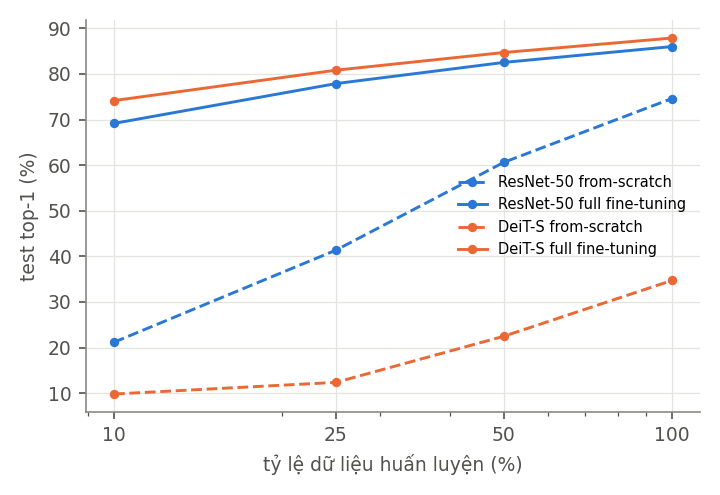

curves.png


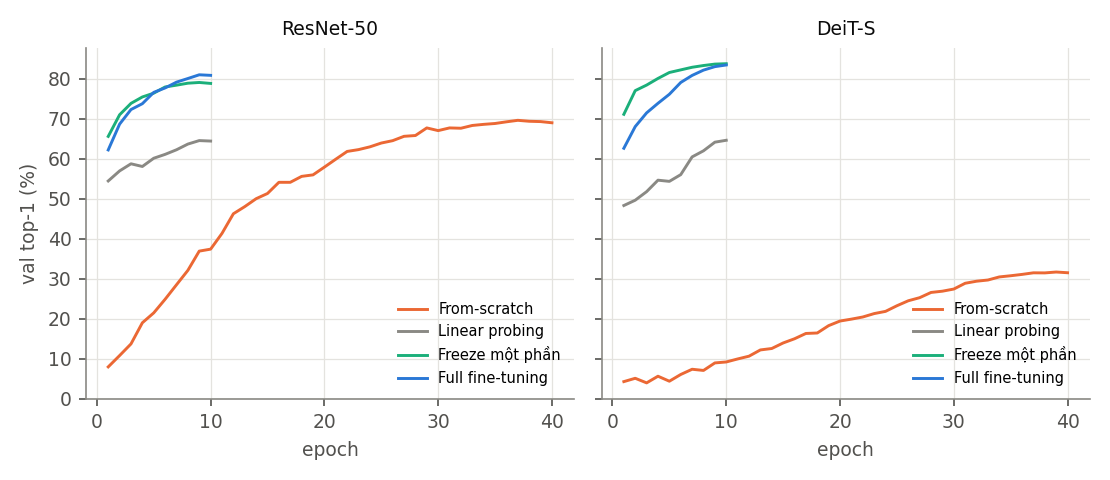

lr_sweep.png


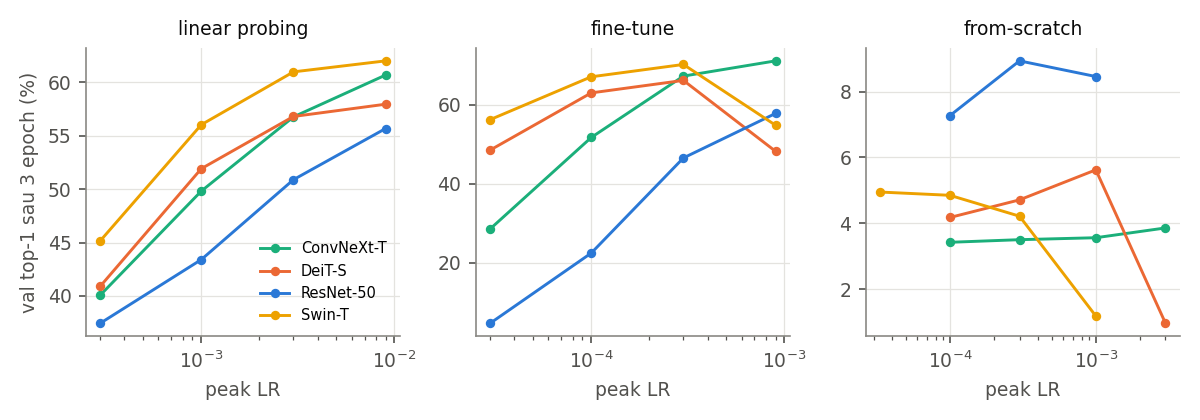

pareto.png


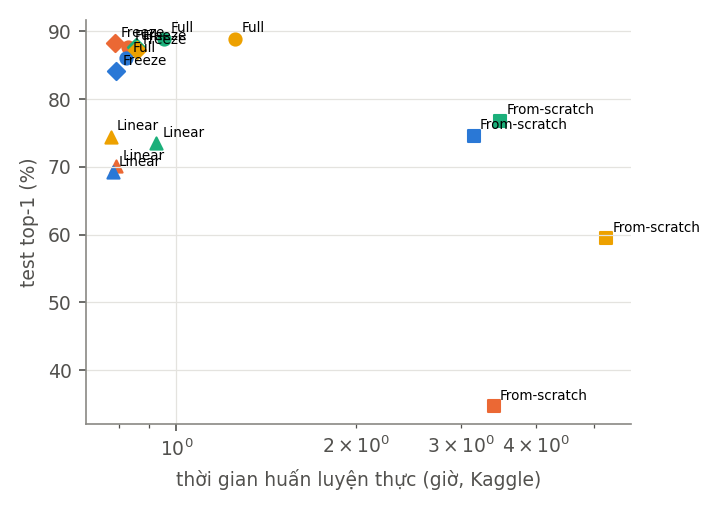

--- tab_ablation.tex
ResNet-50 & From-scratch & 21{,}17 & 41{,}37 & 60{,}64 & 74{,}61 & +53{,}4 \\
ResNet-50 & Full fine-tuning & 69{,}16 & 77{,}89 & 82{,}54 & 86{,}01 & +16{,}8 \\
DeiT-S & From-scratch & 9{,}82 & 12{,}38 & 22{,}50 & 34{,}72 & +24{,}9 \\
DeiT-S & Full fine-tuning & 74{,}17 & 80{,}84 & 84{,}71 & 87{,}88 & +13{,}7

--- tab_acc.tex
CNN & ResNet-50 & From-scratch & 100{,}0\% & 74{,}61 & 92{,}83 & 74{,}19 \\
CNN & ResNet-50 & Linear probing & 0{,}9\% & 69{,}25 $\pm$ 0{,}24 & 90{,}42 $\pm$ 0{,}10 & 68{,}85 $\pm$ 0{,}25 \\
CNN & ResNet-50 & Freeze một phần (layer4 + đầu ra) & 64{,}0\% & 84{,}09 $\pm$ 0{,}08 & 96{,}63 $\pm$ 0{,}06 & 84{,}06 $\pm$ 0{,}08 \\
CNN & ResNet-50 & Full fine-tuning & 100{,}0\% & 85{,}99 $\pm$ 0{,}07 & 97{,}16 $\pm$ 0{,}04 & 85{,}95 $\pm$ 0{,}06 \\
Transformer & DeiT-S & From-scratch & 100{,}0\% & 34{,}72 & 63{,}49 & 31{,}94 \\
Transformer & DeiT-S & Linear probing & 0{,}2\% & 70{,}12 $\pm$ 0{,}11 & 90{,}79 $\pm$ 0{,}04 & 69{,}82 $\pm$ 0{,}14 \\
Transf

In [12]:
# 6. Show the regenerated figures and tables (load mode)
from pathlib import Path
if MODE == "load":
    nu.show_pngs("A1/regenerated/figures")
    for f in sorted(Path("A1/regenerated").glob("tab_*.tex")):
        print("---", f.name); print(f.read_text(encoding="utf8"))

Published results are never overwritten by this notebook. To use your own outputs in the report, copy `A1/regenerated/tab_*.tex` and the figures where the report expects them.